# Phase 6 — Évaluation finale et optimisation business du seuil

**Objectif :** mesurer honnêtement la performance du modèle sur des clients jamais vus, puis transformer ses probabilités en **décision rentable** : qui contacter, et pour quel gain.

**Plan**
1. Évaluation finale sur le jeu de test
2. Choix de la règle de ciblage (seuil) et gain net de la campagne
3. Courbes de gain et de lift : cibler avec un budget limité
4. Sensibilité aux hypothèses économiques

**Règle d'or :** toutes les décisions (seuil compris) sont prises sur le **jeu d'entraînement**. Le jeu de test sert uniquement à **mesurer** le résultat de ces décisions.

**Hypothèses économiques** (cadrage, Phase 0) : action de rétention à 50 $, 30 % des partants contactés restent, valeur d'un client retenu = 12 mois de facture.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import average_precision_score, roc_auc_score, brier_score_loss
from sklearn.calibration import calibration_curve

from churn.config import RANDOM_STATE, DEFAULT_BUSINESS
from churn.data import load_clean
from churn.features import split_data
from churn.models import load_model
from churn.viz import set_style, save_fig, fmt_pct, fmt_int, BLUE, ORANGE, AQUA, TEXT, TEXT_SECONDARY, GRID, SURFACE

warnings.filterwarnings("ignore", category=UserWarning)
set_style()
dec = lambda v, d=3: f"{v:.{d}f}".replace(".", ",")      # virgule décimale
usd = lambda v: f"{fmt_int(v)} $"

X_train, X_test, y_train, y_test = split_data(load_clean())
model, card = load_model("churn_model")
proba_test = model.predict_proba(X_test)[:, 1]
print(f"Modèle : {card['model']} — entraîné le {card['created_at'][:10]} sur {fmt_int(card['n_train'])} clients")
print(f"Jeu de test : {fmt_int(len(X_test))} clients jamais vus, {fmt_pct(y_test.mean())} de churn")

Modèle : Régression logistique (optimisée) — entraîné le 2026-11-19 sur 5 634 clients
Jeu de test : 1 409 clients jamais vus, 26,5 % de churn


## 1. Évaluation finale sur le jeu de test

Un score sur 1 409 clients reste soumis au hasard de l'échantillon. On l'accompagne d'un **intervalle de confiance à 95 % par bootstrap** : on rééchantillonne le jeu de test 1 000 fois (tirage avec remise) et on regarde la dispersion des scores.

In [2]:
metrics = {"pr_auc": average_precision_score, "roc_auc": roc_auc_score, "brier": brier_score_loss}
y_arr = y_test.to_numpy()
rng = np.random.default_rng(RANDOM_STATE)
boot = []
for _ in range(1000):
    idx = rng.integers(0, len(y_arr), len(y_arr))
    boot.append({k: f(y_arr[idx], proba_test[idx]) for k, f in metrics.items()})
boot = pd.DataFrame(boot)

evaluation = pd.DataFrame({
    "validation croisée (train)": {k: card[f"cv_{k}"] for k in metrics},
    "test": {k: f(y_arr, proba_test) for k, f in metrics.items()},
    "IC 95 % bas": boot.quantile(0.025),
    "IC 95 % haut": boot.quantile(0.975),
})
evaluation.index = ["PR-AUC", "ROC-AUC", "Brier"]
evaluation.style.format("{:.4f}")

,validation croisée (train),test,IC 95 % bas,IC 95 % haut
PR-AUC,0.6746,0.6653,0.6151,0.7140
ROC-AUC,0.8511,0.8481,0.8264,0.8688
Brier,0.1326,0.1345,0.1236,0.1444


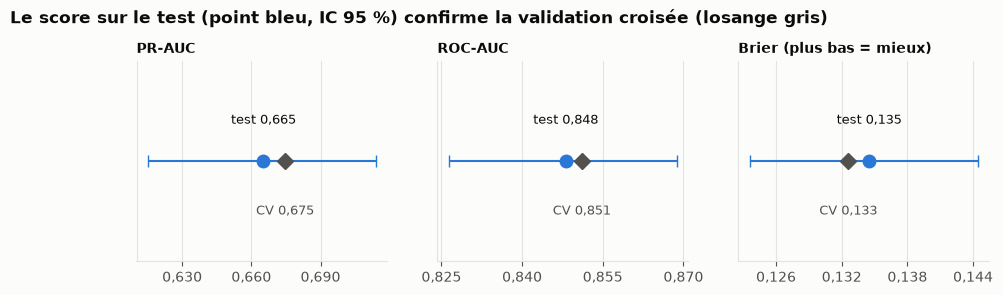

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(11, 2.6))
for ax, (name, row) in zip(axes, evaluation.iterrows()):
    ax.errorbar(row["test"], 0, xerr=[[row["test"] - row["IC 95 % bas"]], [row["IC 95 % haut"] - row["test"]]],
                fmt="o", markersize=9, color=BLUE, ecolor=BLUE, elinewidth=1.5, capsize=4)
    ax.plot(row["validation croisée (train)"], 0, marker="D", markersize=8, color=TEXT_SECONDARY, ls="none")
    ax.text(row["test"], 0.3, f"test {dec(row['test'])}", ha="center", fontsize=9, color=TEXT)
    ax.text(row["validation croisée (train)"], -0.35, f"CV {dec(row['validation croisée (train)'])}",
            ha="center", va="top", fontsize=9, color=TEXT_SECONDARY)
    ax.set_ylim(-0.8, 0.8)
    ax.set_yticks([])
    ax.grid(axis="y", visible=False)
    ax.xaxis.set_major_locator(plt.MaxNLocator(4))
    ax.xaxis.set_major_formatter(lambda v, _: dec(v, 3))
    ax.set_title(name + (" (plus bas = mieux)" if name == "Brier" else ""), fontsize=10)
fig.suptitle("Le score sur le test (point bleu, IC 95 %) confirme la validation croisée (losange gris)",
             x=0.01, ha="left", fontsize=12, fontweight="bold", color=TEXT, y=1.08)
save_fig(fig, "06_test_vs_cv.png")
plt.show()

**Lecture :** sur des clients jamais vus, le modèle obtient une **PR-AUC de 0,665** (IC 95 % : 0,615 – 0,714), une **ROC-AUC de 0,848** et un **Brier de 0,135**. Les scores de validation croisée tombent **à l'intérieur** des intervalles : la Phase 5 n'était pas optimiste, le modèle **généralise** comme prévu.

Pour situer : un classement au hasard donnerait une PR-AUC égale au taux de churn (0,265). Le modèle fait **2,5 fois mieux**.

### 1.1 Les probabilités sont-elles fiables sur le test ?

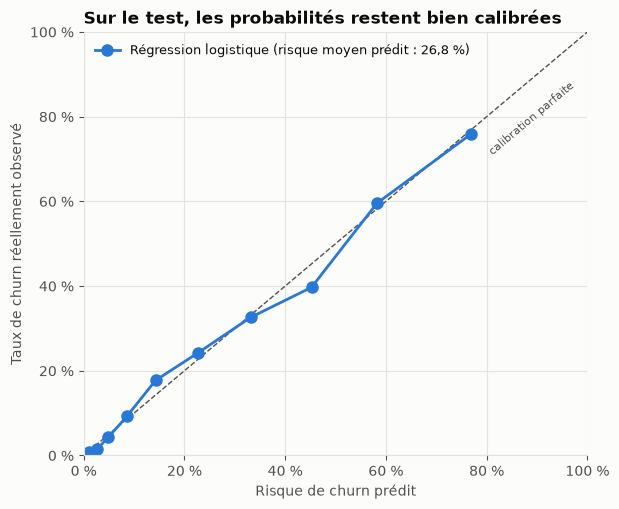

Taux de churn réel du test : 26,5 %


In [4]:
frac_pos, mean_pred = calibration_curve(y_test, proba_test, n_bins=10, strategy="quantile")
fig, ax = plt.subplots(figsize=(6.5, 5.5))
ax.plot([0, 1], [0, 1], ls="--", lw=1, color=TEXT_SECONDARY)
ax.text(0.80, 0.71, "calibration parfaite", rotation=40, fontsize=8, color=TEXT_SECONDARY)
ax.plot(mean_pred, frac_pos, marker="o", markersize=8, lw=2, color=BLUE,
        label=f"Régression logistique (risque moyen prédit : {fmt_pct(proba_test.mean())})")
ax.set(xlim=(0, 1), ylim=(0, 1), xlabel="Risque de churn prédit", ylabel="Taux de churn réellement observé")
ax.xaxis.set_major_formatter(lambda v, _: fmt_pct(v, 0))
ax.yaxis.set_major_formatter(lambda v, _: fmt_pct(v, 0))
ax.legend(loc="upper left", fontsize=9)
ax.set_title("Sur le test, les probabilités restent bien calibrées")
save_fig(fig, "06_calibration_test.png")
plt.show()
print(f"Taux de churn réel du test : {fmt_pct(y_test.mean())}")

**Lecture :** la courbe suit la diagonale et le risque moyen prédit (26,8 %) colle au taux réel (26,5 %). C'est la condition pour la suite : on va **multiplier ces probabilités par des dollars**. Des probabilités biaisées donneraient des gains faux.

## 2. Qui contacter ? Choix de la règle de ciblage

Le modèle donne une probabilité ; l'équipe marketing a besoin d'une **liste de clients à appeler**. Le seuil de 0,5 par défaut n'a aucune justification économique. On compare deux façons de décider :

1. **Un seuil unique** : contacter si `p ≥ s`, avec `s` choisi pour maximiser le gain net.
2. **La règle du gain espéré** : contacter si le gain espéré est positif, c'est-à-dire si

$$p \times 0{,}30 \times 12 \times \text{MonthlyCharges} > 50 \iff p > \frac{50}{3{,}6 \times \text{MonthlyCharges}}$$

Le seuil devient **propre à chaque client** : un client qui paie 110 $/mois vaut la peine d'être contacté dès 13 % de risque, un client à 20 $/mois seulement au-delà de 69 %. Cette règle n'a **aucun paramètre à régler**, mais elle n'est valable que si les probabilités sont **calibrées** (vérifié en section 1.1).

**Pour choisir sans toucher au test**, on utilise les **prédictions hors pli** du jeu d'entraînement : chaque client d'entraînement est prédit par un modèle qui ne l'a pas vu (validation croisée à 5 plis).

In [5]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from churn.business import (best_threshold, breakeven_proba, campaign_gain, expected_gain,
                            lift_table, targeting_curve, threshold_curve)

mc_train, mc_test = X_train["MonthlyCharges"], X_test["MonthlyCharges"]
oof = cross_val_predict(model, X_train, y_train, method="predict_proba",
                        cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE))[:, 1]

curve_train = threshold_curve(y_train, oof, mc_train)
best_s = best_threshold(curve_train)
train_rules = pd.DataFrame({
    "Seuil 0,5": campaign_gain(y_train, oof >= 0.5, mc_train),
    f"Seuil optimisé ({dec(best_s, 2)})": campaign_gain(y_train, oof >= best_s, mc_train),
    "Gain espéré > 0": campaign_gain(y_train, expected_gain(oof, mc_train) > 0, mc_train),
}).T
train_rules[["n_targeted", "precision", "recall", "net_gain"]].style.format(
    {"n_targeted": "{:.0f}", "precision": "{:.1%}", "recall": "{:.1%}", "net_gain": "{:,.0f} $"})

,n_targeted,precision,recall,net_gain
"Seuil 0,5",1189,67.6%,53.8%,"173,735 $"
"Seuil optimisé (0,19)",2755,47.6%,87.8%,"221,657 $"
Gain espéré > 0,2469,49.2%,81.3%,"231,191 $"


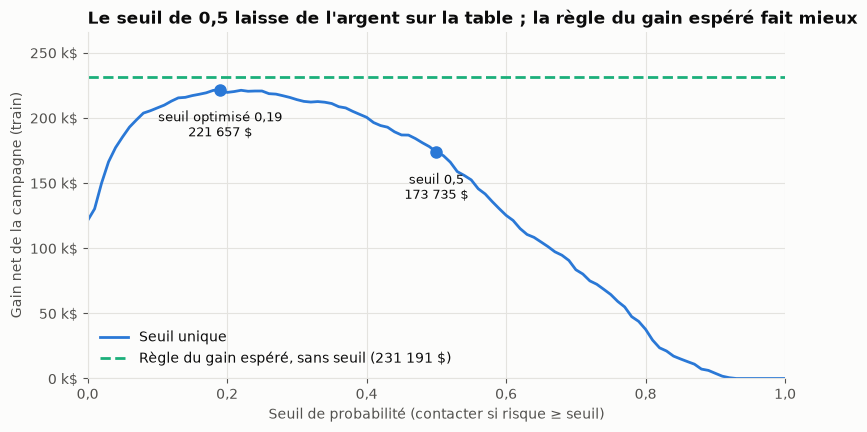

In [6]:
eg_train = train_rules.loc["Gain espéré > 0", "net_gain"]
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(curve_train.index, curve_train["net_gain"] / 1e3, lw=2, color=BLUE, label="Seuil unique")
ax.axhline(eg_train / 1e3, color=AQUA, lw=2, ls="--", label=f"Règle du gain espéré, sans seuil ({usd(eg_train)})")
for s, label in [(0.5, "seuil 0,5"), (best_s, f"seuil optimisé {dec(best_s, 2)}")]:
    g = curve_train.loc[s, "net_gain"] / 1e3
    ax.plot(s, g, "o", markersize=8, color=BLUE)
    ax.annotate(f"{label}\n{usd(g * 1e3)}", (s, g), xytext=(0, -14), textcoords="offset points",
                ha="center", va="top", fontsize=9, color=TEXT)
ax.set_xlim(0, 1)
ax.set_ylim(0, eg_train / 1e3 * 1.15)
ax.xaxis.set_major_formatter(lambda v, _: dec(v, 1))
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0f} k$")
ax.set_xlabel("Seuil de probabilité (contacter si risque ≥ seuil)")
ax.set_ylabel("Gain net de la campagne (train)")
ax.legend(loc="lower left")
ax.set_title("Le seuil de 0,5 laisse de l'argent sur la table ; la règle du gain espéré fait mieux")
save_fig(fig, "06_gain_seuil.png")
plt.show()

**Lecture (jeu d'entraînement) :**
- Le **seuil optimal est bas** (autour de 0,2), loin du 0,5 par défaut : rater un partant coûte plus cher qu'une fausse alerte, il est rentable de contacter large.
- La courbe forme un **plateau** entre 0,15 et 0,25 : le choix exact du seuil importe peu, ce qui rend la décision **robuste**.
- La **règle du gain espéré** fait encore mieux, en contactant **moins** de clients : elle concentre l'effort sur ceux qui ont de la valeur.

**Décision (prise sur le train) : on adopte la règle du gain espéré.** On mesure maintenant le résultat sur le test.

### 2.1 À quoi ressemble cette règle ?

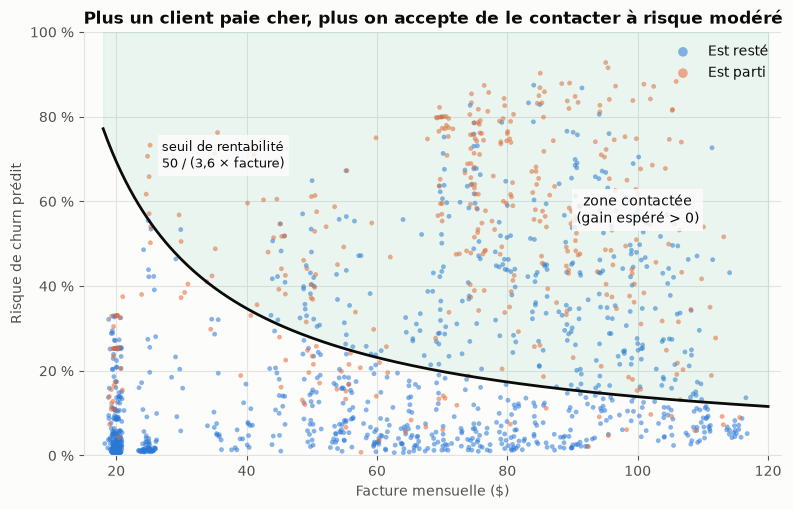

Clients du test contactés : 615 sur 1409 (43,6 %)


In [7]:
fig, ax = plt.subplots(figsize=(9, 5.5))
targeted = expected_gain(proba_test, mc_test) > 0
for label, color in [(0, BLUE), (1, ORANGE)]:
    mask = y_test.to_numpy() == label
    ax.scatter(mc_test[mask], proba_test[mask], s=12, alpha=0.55, color=color, edgecolor="none",
               label="Est parti" if label else "Est resté")
grid = np.linspace(18, 120, 300)
ax.plot(grid, breakeven_proba(grid), color=TEXT, lw=2)
ax.fill_between(grid, breakeven_proba(grid), 1, color=AQUA, alpha=0.08)
box = dict(facecolor=SURFACE, edgecolor="none", alpha=0.85, pad=3)
ax.text(100, 0.55, "zone contactée\n(gain espéré > 0)", fontsize=10, color=TEXT, ha="center", bbox=box)
ax.text(27, 0.68, "seuil de rentabilité\n50 / (3,6 × facture)", fontsize=9, color=TEXT, bbox=box)
ax.set(xlim=(15, 122), ylim=(0, 1), xlabel="Facture mensuelle ($)", ylabel="Risque de churn prédit")
ax.yaxis.set_major_formatter(lambda v, _: fmt_pct(v, 0))
ax.legend(loc="upper right", markerscale=2)
ax.set_title("Plus un client paie cher, plus on accepte de le contacter à risque modéré")
save_fig(fig, "06_regle_gain_espere.png")
plt.show()
print(f"Clients du test contactés : {targeted.sum()} sur {len(targeted)} ({fmt_pct(targeted.mean())})")

### 2.2 Résultat sur le jeu de test : comparaison des stratégies

On compare la règle retenue aux stratégies naïves (critère de succès n° 2 du cadrage), et à l'**oracle** : un devin qui contacterait exactement les partants. L'oracle est inatteignable, mais il donne le **plafond** du gain possible.

In [8]:
y_np = y_test.to_numpy()
strategies = {
    "Ne contacter personne": np.zeros(len(y_np), dtype=bool),
    "Contacter tout le monde": np.ones(len(y_np), dtype=bool),
    "Seuil 0,5 (par défaut)": proba_test >= 0.5,
    f"Seuil optimisé sur le train ({dec(best_s, 2)})": proba_test >= best_s,
    "Gain espéré > 0 (retenue)": targeted,
    "Oracle (plafond théorique)": y_np == 1,
}
results = pd.DataFrame({k: campaign_gain(y_test, t, mc_test) for k, t in strategies.items()}).T
oracle_gain = results.loc["Oracle (plafond théorique)", "net_gain"]
results["part du plafond"] = results["net_gain"] / oracle_gain
results[["n_targeted", "true_positives", "false_positives", "precision", "recall", "cost", "net_gain",
         "part du plafond"]].style.format(
    {"n_targeted": "{:.0f}", "true_positives": "{:.0f}", "false_positives": "{:.0f}", "precision": "{:.1%}",
     "recall": "{:.1%}", "cost": "{:,.0f} $", "net_gain": "{:,.0f} $", "part du plafond": "{:.0%}"}, na_rep="—")

,n_targeted,true_positives,false_positives,precision,recall,cost,net_gain,part du plafond
Ne contacter personne,0,0,0,—,0.0%,0 $,0 $,0%
Contacter tout le monde,1409,374,1035,26.5%,100.0%,"70,450 $","27,524 $",35%
"Seuil 0,5 (par défaut)",293,196,97,66.9%,52.4%,"14,650 $","40,087 $",51%
"Seuil optimisé sur le train (0,19)",685,322,363,47.0%,86.1%,"34,250 $","51,370 $",65%
Gain espéré > 0 (retenue),615,295,320,48.0%,78.9%,"30,750 $","53,311 $",67%
Oracle (plafond théorique),374,374,0,100.0%,100.0%,"18,700 $","79,274 $",100%


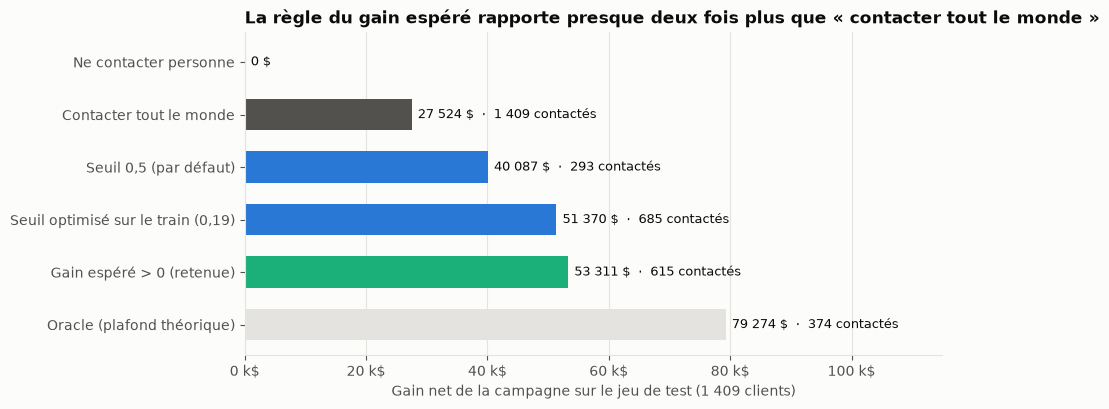

In [9]:
r = results.iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 4.2))
colors = [GRID if "Oracle" in n else AQUA if "retenue" in n else BLUE if "Seuil" in n else TEXT_SECONDARY
          for n in r.index]
ax.barh(r.index, r["net_gain"] / 1e3, color=colors, height=0.6)
for i, (name, row) in enumerate(r.iterrows()):
    txt = usd(row["net_gain"]) + (f"  ·  {fmt_int(row['n_targeted'])} contactés" if row["n_targeted"] else "")
    ax.text(row["net_gain"] / 1e3 + 1, i, txt, va="center", fontsize=9, color=TEXT)
ax.set_xlim(0, oracle_gain / 1e3 * 1.45)
ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0f} k$")
ax.grid(axis="y", visible=False)
ax.set_xlabel(f"Gain net de la campagne sur le jeu de test ({fmt_int(len(y_np))} clients)")
ax.set_title("La règle du gain espéré rapporte presque deux fois plus que « contacter tout le monde »")
save_fig(fig, "06_strategies.png")
plt.show()

**L'écart est-il solide ?** Même bootstrap qu'en section 1 : on rejoue la comparaison sur 1 000 rééchantillonnages du test.

In [10]:
rng = np.random.default_rng(RANDOM_STATE)
mc_np = mc_test.to_numpy()
pairs = {"vs seuil 0,5": strategies["Seuil 0,5 (par défaut)"],
         f"vs seuil optimisé ({dec(best_s, 2)})": strategies[f"Seuil optimisé sur le train ({dec(best_s, 2)})"],
         "vs contacter tout le monde": strategies["Contacter tout le monde"]}
diffs = {k: [] for k in pairs}
for _ in range(1000):
    idx = rng.integers(0, len(y_np), len(y_np))
    g_rule = campaign_gain(y_np[idx], targeted[idx], mc_np[idx])["net_gain"]
    for k, t in pairs.items():
        diffs[k].append(g_rule - campaign_gain(y_np[idx], t[idx], mc_np[idx])["net_gain"])
pd.DataFrame({k: {"écart moyen": np.mean(v), "IC 95 % bas": np.percentile(v, 2.5),
                  "IC 95 % haut": np.percentile(v, 97.5), "part des tirages > 0": np.mean(np.array(v) > 0)}
              for k, v in diffs.items()}).T.style.format(
    {"écart moyen": "{:+,.0f} $", "IC 95 % bas": "{:+,.0f} $", "IC 95 % haut": "{:+,.0f} $",
     "part des tirages > 0": "{:.0%}"})

,écart moyen,IC 95 % bas,IC 95 % haut,part des tirages > 0
"vs seuil 0,5","+13,185 $","+7,985 $","+18,275 $",100%
"vs seuil optimisé (0,19)","+1,954 $",-118 $,"+4,367 $",96%
vs contacter tout le monde,"+25,875 $","+22,206 $","+29,432 $",100%


In [11]:
rule = results.loc["Gain espéré > 0 (retenue)"]
per_1000 = rule["net_gain"] / len(y_np) * 1000
n_base = len(load_clean())
print(f"Gain net sur le test : {usd(rule['net_gain'])} pour {fmt_int(rule['n_targeted'])} clients contactés "
      f"({dec(rule['net_gain'] / rule['cost'], 2)} $ de gain net par $ dépensé)")
print(f"Soit {usd(per_1000)} pour 1 000 clients, "
      f"et ~{usd(round(per_1000 * n_base / 1000, -3))} par campagne extrapolé à la base de {fmt_int(n_base)} clients")

Gain net sur le test : 53 311 $ pour 615 clients contactés (1,73 $ de gain net par $ dépensé)
Soit 37 836 $ pour 1 000 clients, et ~266 000 $ par campagne extrapolé à la base de 7 043 clients


**Résultat sur le test (clients jamais vus) :**
- La règle du gain espéré dégage **53 311 $** en contactant 615 clients sur 1 409, soit **67 % du plafond théorique** atteint par un devin.
- C'est **presque deux fois** le gain de « contacter tout le monde » (27 524 $) et **+33 %** par rapport au seuil de 0,5 (40 087 $). Ces écarts sont **solides** (intervalles bootstrap entièrement positifs).
- Face au seuil optimisé (51 370 $), l'avantage (+1 954 $) va dans le même sens que sur le train mais reste **à la limite du bruit** (positif dans 96 % des tirages). Argument décisif : la règle obtient ce gain en contactant **70 clients de moins**, sans aucun paramètre à régler.
- Le seuil optimisé sur le train (0,19) est presque identique au meilleur seuil a posteriori sur le test (0,18) : la décision **généralise**.

**Critère de succès n° 2 du cadrage : atteint.** La campagne guidée par le modèle bat les deux stratégies naïves.